# Module III: Convolutional neural networks
A CNN classifier on rasterised partial sketches (64x64), compared with the MLP baseline. Below, the trained CNN is run on real held-out test sketches.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, inspect
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda m: json.load(open(ROOT / "runs" / m / "results.json"))
from src.models.nets import CNNEncoder
print(inspect.getsource(CNNEncoder))

class CNNEncoder(nn.Module):
    """64x64 -> 256-d. Module III."""
    out_dim = 256

    def __init__(self):
        super().__init__()
        # Stride-2 stem + narrow early stages keep it fast on a CPU (~40M MACs per sketch).
        self.body = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True),  # 32
            conv_block(16, 32), nn.MaxPool2d(2),    # 16
            conv_block(32, 64), nn.MaxPool2d(2),    # 8
            conv_block(64, 128), nn.MaxPool2d(2),   # 4
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.fc(self.body(x))



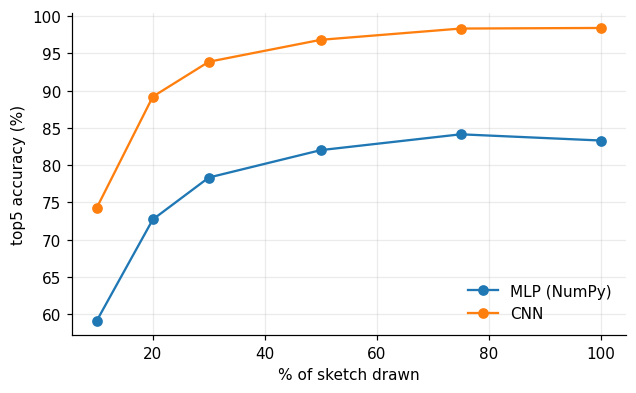

In [2]:
def curve(models, metric="top5"):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for m, label in models.items():
        r = res(m); xs = sorted(r, key=float)
        ax.plot([float(x) * 100 for x in xs], [r[x][metric] * 100 for x in xs], marker="o", label=label)
    ax.set(xlabel="% of sketch drawn", ylabel=f"{metric} accuracy (%)"); ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()
curve({'mlp': 'MLP (NumPy)', 'cnn': 'CNN'})

## Live predictions on held-out sketches (30% drawn)

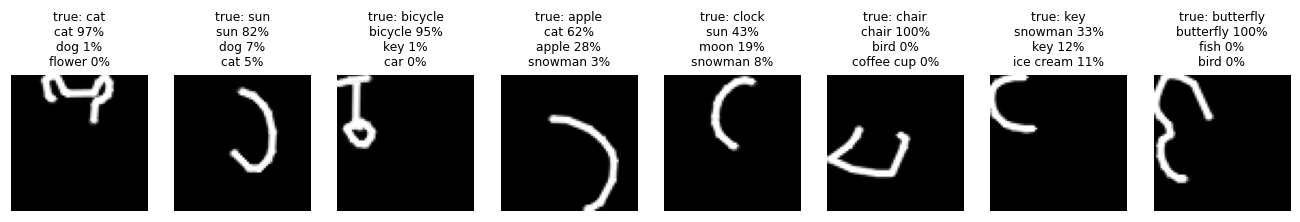

In [3]:
import torch
from src.models.nets import build
from src.data.dataset import eval_set, as_float
from src.common import CLASSES
net = build('cnn'); net.load_state_dict(torch.load(ROOT / 'runs' / 'cnn' / 'best.pt', map_location='cpu')); net.eval()
d = eval_set('test')[0.3]
idx = np.arange(0, len(d['y']), 1100)[:8]
b = as_float({k: v[idx] for k, v in d.items()})
with torch.no_grad(): p = torch.softmax(net(b['img'], b['seq'], b['len'])[0], 1)
fig, ax = plt.subplots(1, 8, figsize=(15, 2.4))
for k in range(8):
    top = p[k].topk(3)
    ax[k].imshow(b['img'][k, 0], cmap='gray'); ax[k].axis('off')
    ax[k].set_title(f"true: {CLASSES[b['y'][k]]}\n" + '\n'.join(f'{CLASSES[i]} {v:.0%}' for v, i in zip(top.values, top.indices)), fontsize=8)
plt.show()